In [9]:
import sys
import os

# Thêm thư mục gốc của dự án vào đường dẫn tìm kiếm module của Python
sys.path.append(os.path.abspath('..'))

import pandas as pd
from src.data_prep import load_and_clean_data, split_train_test

# Nạp và làm sạch data
df = load_and_clean_data('../data/raw/gas_turbine_data.csv')

print("Đã import src và load data thành công!")

Đã import src và load data thành công!


In [10]:
# Chia tập
X_train, y_train, X_test, y_test = split_train_test(df)

# Nối X và y lại rồi tự lưu ra file trên máy
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

train_df.to_csv('../data/processed/train.csv', index=False)
test_df.to_csv('../data/processed/test.csv', index=False)

print("Đã tạo xong train.csv và test.csv sạch sẽ!")

Đã tạo xong train.csv và test.csv sạch sẽ!


In [11]:
from src.models import build_xgboost_model

model = build_xgboost_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [12]:
y_pred

array([[  3.1729586,  77.76272  ],
       [  2.97429  ,  77.80868  ],
       [  2.7539492,  73.467064 ],
       ...,
       [  8.01801  , 107.06805  ],
       [  1.8521028,  85.64815  ],
       [  3.5917969,  89.57772  ]], shape=(14535, 2), dtype=float32)

In [13]:
from src.evaluation import evaluate_regression

results_co = evaluate_regression(y_test.iloc[:, 0], y_pred[:, 0], model_name="XGBoost Baseline - CO")
results_nox = evaluate_regression(y_test.iloc[:, 1], y_pred[:, 1], model_name="XGBoost Baseline - NOX")

=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Baseline - CO ===
MSE  : 1.4230
RMSE : 1.1929
MAE  : 0.8658
R2   : 0.5708
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Baseline - NOX ===
MSE  : 174.3442
RMSE : 13.2039
MAE  : 11.4513
R2   : -0.5585


In [14]:
import time
from src.models import tune_xgboost
from src.evaluation import evaluate_regression

# 1. Tách biến mục tiêu
y_train_co, y_test_co = y_train.iloc[:, 0], y_test.iloc[:, 0]
y_train_nox, y_test_nox = y_train.iloc[:, 1], y_test.iloc[:, 1]

# 2. Tuning cho CO
print("--- Đang Tuning cho mô hình CO ---")
start_time_co = time.time()

best_model_co, best_params_co, cv_results_co = tune_xgboost(X_train, y_train_co)

time_co = time.time() - start_time_co
print(f"[THỜI GIAN TUNING CO]: {time_co:.2f}s")
print("[BỘ THAM SỐ TỐI ƯU CHO CO]:", best_params_co)

y_pred_co_tuned = best_model_co.predict(X_test)
results_co_tuned = evaluate_regression(y_test_co, y_pred_co_tuned, model_name="XGBoost Tuned - CO")

# 3. Tuning cho NOX
print("\n--- Đang Tuning cho mô hình NOX ---")
start_time_nox = time.time()

best_model_nox, best_params_nox, cv_results_nox = tune_xgboost(X_train, y_train_nox)

time_nox = time.time() - start_time_nox
print(f"[THỜI GIAN TUNING NOX]: {time_nox:.2f}s")
print("[BỘ THAM SỐ TỐI ƯU CHO NOX]:", best_params_nox)

y_pred_nox_tuned = best_model_nox.predict(X_test)
results_nox_tuned = evaluate_regression(y_test_nox, y_pred_nox_tuned, model_name="XGBoost Tuned - NOX")

--- Đang Tuning cho mô hình CO ---
Fitting 3 folds for each of 15 candidates, totalling 45 fits
[THỜI GIAN TUNING CO]: 16.09s
[BỘ THAM SỐ TỐI ƯU CHO CO]: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - CO ===
MSE  : 1.1225
RMSE : 1.0595
MAE  : 0.7546
R2   : 0.6615

--- Đang Tuning cho mô hình NOX ---
Fitting 3 folds for each of 15 candidates, totalling 45 fits
[THỜI GIAN TUNING NOX]: 10.43s
[BỘ THAM SỐ TỐI ƯU CHO NOX]: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - NOX ===
MSE  : 155.2609
RMSE : 12.4604
MAE  : 11.0844
R2   : -0.3879


In [15]:
import time
from sklearn.metrics import r2_score
import xgboost as xgb

# 1. Với XGBoost Baseline (CO):
t0 = time.time()
xgb_base = xgb.XGBRegressor(random_state=42)
xgb_base.fit(X_train, y_train_co)
time_base = time.time() - t0

r2_train_base = r2_score(y_train_co, xgb_base.predict(X_train))
print(f"XGB Baseline CO - R2_train: {r2_train_base:.4f}, Thời gian fit: {time_base:.4f}s")

# 2. Với XGBoost Tuned (CO) - best_model_co đã có từ RandomizedSearch:
y_train_pred_tuned = best_model_co.predict(X_train)
r2_train_tuned = r2_score(y_train_co, y_train_pred_tuned)
print(f"XGB Tuned CO - R2_train: {r2_train_tuned:.4f}")

XGB Baseline CO - R2_train: 0.9273, Thời gian fit: 0.3260s
XGB Tuned CO - R2_train: 0.8233


In [16]:
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import wilcoxon
import numpy as np

# Huấn luyện nhanh Random Forest đối chứng
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train_co)
y_pred_rf = rf.predict(X_test)

# So sánh với XGBoost Tuned của bạn
e_xgb = np.abs(y_test_co.values - y_pred_co_tuned)
e_rf  = np.abs(y_test_co.values - y_pred_rf)

stat, p_val = wilcoxon(e_xgb, e_rf)
print(f"Delta MAE: {e_xgb.mean() - e_rf.mean():.4f}")
print(f"p-value: {p_val:.3e}")

Delta MAE: -0.0700
p-value: 1.927e-76


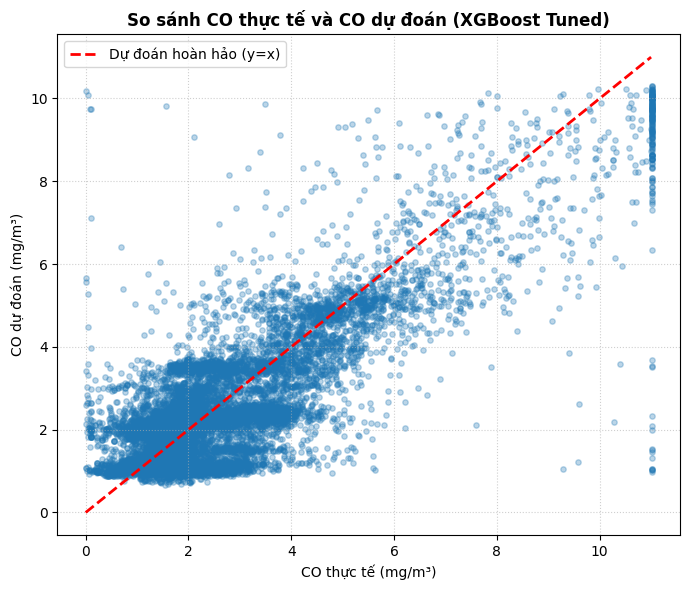

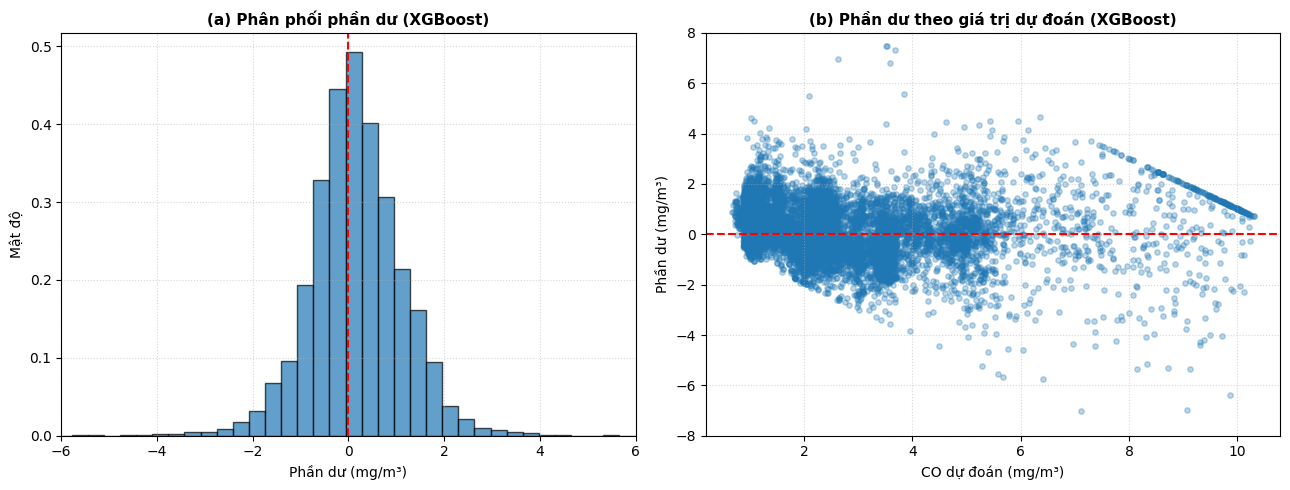

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Tính phần dư của XGBoost Tuned (CO)
residuals_xgb = y_test_co.values - y_pred_co_tuned

# 1. Vẽ hình Actual vs Predicted của XGBoost
plt.figure(figsize=(7, 6))
plt.scatter(
    y_test_co.values, y_pred_co_tuned, alpha=0.3, s=15, color='#1f77b4'
)
plt.plot(
    [0, 11],
    [0, 11],
    'r--',
    linewidth=2,
    label='Dự đoán hoàn hảo (y=x)',
)
plt.title(
    'So sánh CO thực tế và CO dự đoán (XGBoost Tuned)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('CO thực tế (mg/m³)')
plt.ylabel('CO dự đoán (mg/m³)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(
    '../reports/figures/actual_vs_predicted_xgb.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

# 2. Vẽ 2 hình chẩn đoán phần dư (Residual Distribution & Residual vs Predicted)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Phân phối phần dư
axes[0].hist(
    residuals_xgb,
    bins=60,
    color='#1f77b4',
    edgecolor='black',
    alpha=0.7,
    density=True,
)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title(
    '(a) Phân phối phần dư (XGBoost)', fontsize=11, fontweight='bold'
)
axes[0].set_xlabel('Phần dư (mg/m³)')
axes[0].set_ylabel('Mật độ')
axes[0].set_xlim(-6, 6)
axes[0].grid(True, linestyle=':', alpha=0.5)

# (b) Phần dư theo giá trị dự đoán
axes[1].scatter(
    y_pred_co_tuned, residuals_xgb, alpha=0.3, s=15, color='#1f77b4'
)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title(
    '(b) Phần dư theo giá trị dự đoán (XGBoost)',
    fontsize=11,
    fontweight='bold',
)
axes[1].set_xlabel('CO dự đoán (mg/m³)')
axes[1].set_ylabel('Phần dư (mg/m³)')
axes[1].set_ylim(-8, 8)
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig(
    '../reports/figures/residual_diagnostics_xgb.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

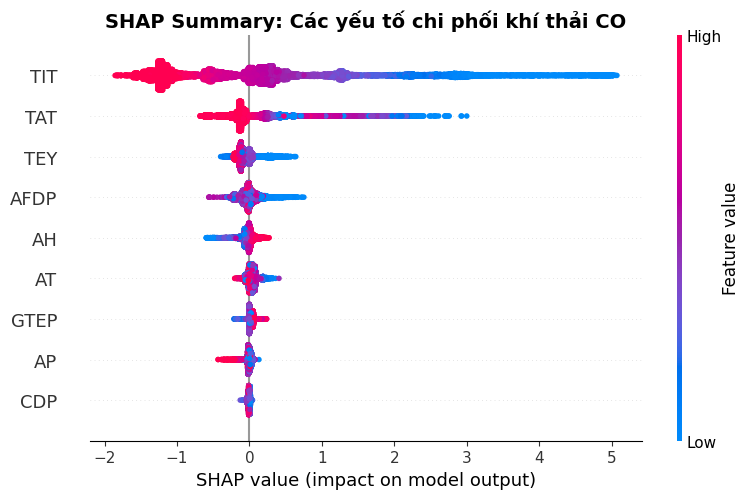

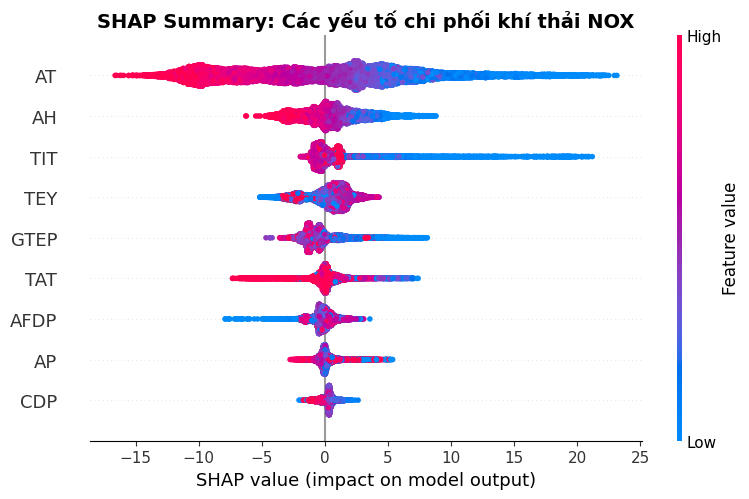

In [18]:
import shap
import matplotlib.pyplot as plt

# Khởi tạo bộ tính toán SHAP cho CO
explainer_co = shap.TreeExplainer(best_model_co)
shap_values_co = explainer_co.shap_values(X_test)

# Khởi tạo bộ tính toán SHAP cho mô hình NOX
explainer_nox = shap.TreeExplainer(best_model_nox)
shap_values_nox = explainer_nox.shap_values(X_test)

# Vẽ biểu đồ Tổng quan (Summary Plot) cho Co
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải CO", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_co, X_test, show=False)
plt.show()

# Vẽ biểu đồ Tổng quan (Summary Plot) cho NOX
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải NOX", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_nox, X_test, show=False)
plt.show()



In [19]:
import joblib
import os
import matplotlib.pyplot as plt
import shap

os.makedirs('../models', exist_ok=True)
os.makedirs('../reports/figures', exist_ok=True)

joblib.dump(best_model_co, '../models/xgboost_tuned_co.pkl')
joblib.dump(best_model_nox, '../models/xgboost_tuned_nox.pkl')
print('Lưu mô hình vào ../models')

# Vẽ biểu đồ Tổng quan (Summary Plot) cho Co
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải CO", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_co, X_test, show=False)
plt.savefig('../reports/figures/shap_summary_co.png', dpi=300, bbox_inches='tight')
plt.close()

# Vẽ biểu đồ Tổng quan (Summary Plot) cho NOX
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải NOX", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_nox, X_test, show=False)
plt.savefig('../reports/figures/shap_summary_nox.png', dpi=300, bbox_inches='tight')
plt.close()




Lưu mô hình vào ../models


In [20]:
import pandas as pd
import os

os.makedirs('../reports/log', exist_ok=True)

cols_to_keep = ['params', 'mean_test_score', 'std_test_score', 'mean_fit_time']

# 1. Trích xuất và lưu lịch sử dò tìm của CO
cv_df_co = pd.DataFrame(cv_results_co)
log_co = cv_df_co[cols_to_keep].sort_values(by='mean_test_score', ascending=False)
log_co.to_csv('../reports/log/tuning_log_co.csv', index=False)

# 2. Trích xuất và lưu lịch sử dò tìm của NOX
cv_df_nox = pd.DataFrame(cv_results_nox)
log_nox = cv_df_nox[cols_to_keep].sort_values(by='mean_test_score', ascending=False)
log_nox.to_csv('../reports/log/tuning_log_nox.csv', index=False)

print("Đã lưu log tuning thành công vào thư mục reports/log/")
log_co.head(3)

Đã lưu log tuning thành công vào thư mục reports/log/


,params,mean_test_score,std_test_score,mean_fit_time
4,"{'subsample': 0.7, 'n_estimators': 300, 'max_d...",0.583710,0.178838,1.314583
5,"{'subsample': 0.8, 'n_estimators': 200, 'max_d...",0.581958,0.154249,0.897494
7,"{'subsample': 1.0, 'n_estimators': 200, 'max_d...",0.562877,0.166507,1.848106


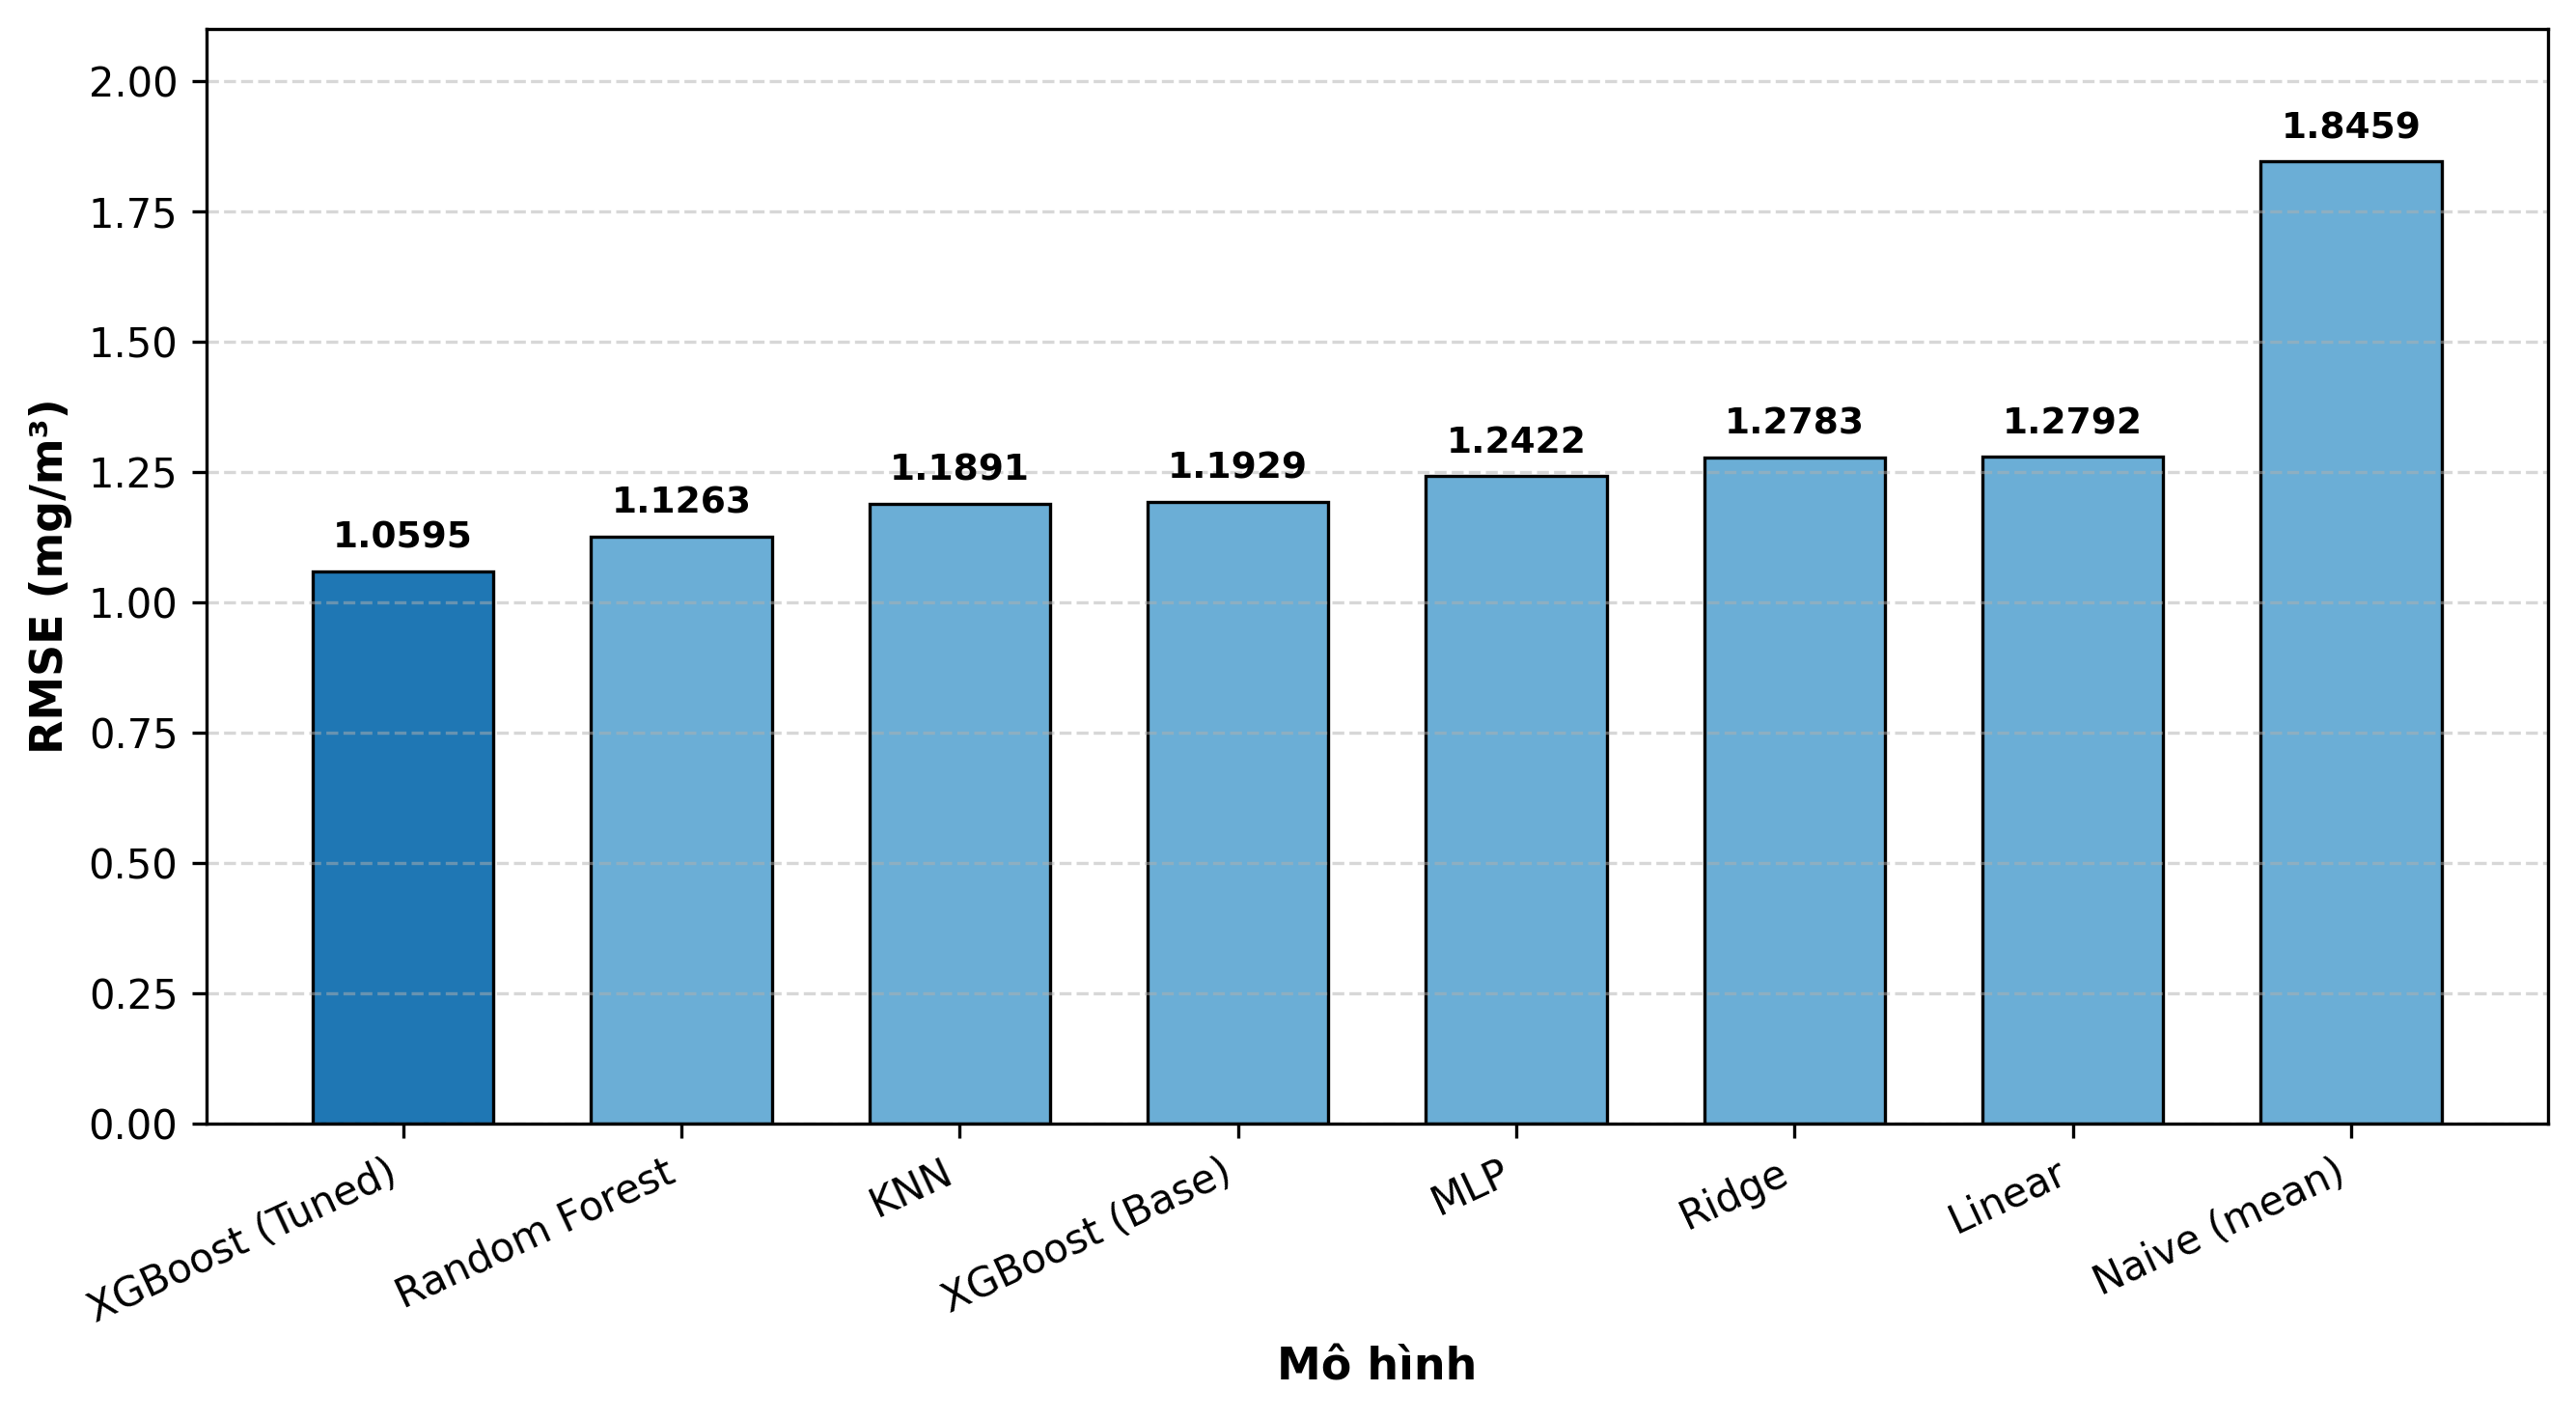

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Dữ liệu RMSE cho biến mục tiêu CO (xếp từ thấp đến cao)
models = [
    'XGBoost (Tuned)', 
    'Random Forest', 
    'KNN', 
    'XGBoost (Base)', 
    'MLP', 
    'Ridge', 
    'Linear', 
    'Naive (mean)'
]

rmse_values = [
    1.0595,  # XGBoost Tuned (Tốt nhất)
    1.1263,  # Random Forest
    1.1891,  # KNN
    1.1929,  # XGBoost Baseline
    1.2422,  # MLP
    1.2783,  # Ridge
    1.2792,  # Linear
    1.8459   # Naive
]

# 2. Thiết lập màu sắc: Tô màu nổi bật cho XGBoost Tuned
colors = ['#1f77b4' if m == 'XGBoost (Tuned)' else '#6baed6' for m in models]

# 3. Khởi tạo biểu đồ
plt.figure(figsize=(9, 5), dpi=300)
bars = plt.bar(models, rmse_values, color=colors, edgecolor='black', linewidth=0.8, width=0.65)

# 4. Hiển thị số liệu chi tiết trên đầu mỗi cột
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0, 
        yval + 0.03, 
        f'{yval:.4f}', 
        ha='center', 
        va='bottom', 
        fontsize=9, 
        fontweight='bold'
    )

# 5. Định dạng trục, lưới và tiêu đề
plt.ylabel('RMSE (mg/m³)', fontsize=11, fontweight='bold')
plt.xlabel('Mô hình', fontsize=11, fontweight='bold')
plt.ylim(0, 2.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=25, ha='right', fontsize=10)

plt.tight_layout()

# 6. Lưu file vào thư mục figures để đưa vào LaTeX
plt.savefig('../reports/figures/model_comparison_rmse.png', dpi=300, bbox_inches='tight')
plt.show()